# PRBD Microscopic Images of Different Processed Rice — Data EDA & Related Work



## 1. Import Required Libraries

In [6]:
import os
import re
import zipfile
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from IPython.display import display

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload Dataset ZIP

In [7]:
from google.colab import files

uploaded = files.upload()

ZIP_PATH = next(iter(uploaded.keys()))

print("Uploaded dataset:", ZIP_PATH)
print("File size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))

Saving PRBD Microscopic Image of Different Processed Rice.zip to PRBD Microscopic Image of Different Processed Rice (1).zip
Uploaded dataset: PRBD Microscopic Image of Different Processed Rice (1).zip
File size (MB): 418.31


## 3. Extract the Dataset

In [8]:
EXTRACT_DIR = "/content/rice_dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Dataset extracted successfully.")

for root, dirs, files_list in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

Dataset extracted successfully.
rice_dataset/
  PRBD Microscopic Image of Different Processed Rice/
    Original_Images/
      Chinigura/
      Swarna/
      Beroi/
      BR-29/
      Katari Najir/
      Ghee Bhog/
      Katari Siddho/
      Aush/
      Miniket/
      BR-28/
    Augmented_images/
      Chinigura/
      Swarna/
      Beroi/
      BR-29/
      Katari Najir/
      Ghee Bhog/
      Katari Siddho/
      Aush/
      Miniket/
      BR-28/


## 4. Create Image Metadata CSV

In [9]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

records = []

for path in Path(EXTRACT_DIR).rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    relative_path = path.relative_to(EXTRACT_DIR)
    parts = relative_path.parts

    # Identify the image category from its parent folder
    folder_names = [p.lower() for p in parts[:-1]]

    if "augmented_images" in folder_names:
        dataset_type = "augmented"
    elif "original_images" in folder_names:
        dataset_type = "original"
    else:
        dataset_type = "unknown"

    # Find the rice class folder
    if dataset_type != "unknown":
        category_index = folder_names.index(
            "augmented_images"
            if dataset_type == "augmented"
            else "original_images"
        )
        label = parts[category_index + 1] if (
            category_index + 1 < len(parts) - 1
        ) else "unknown"
    else:
        label = "unknown"

    filename = path.stem

    # Remove augmentation suffix to approximate the source-image ID
    source_image_id = re.sub(
        r"_aug(?:mented)?[_-]?\d+$",
        "",
        filename,
        flags=re.IGNORECASE
    )

    records.append({
        "image_path": str(path),
        "relative_path": str(relative_path),
        "filename": path.name,
        "label": label,
        "dataset_type": dataset_type,
        "source_image_id": source_image_id,
        "file_extension": path.suffix.lower(),
        "file_size_kb": round(path.stat().st_size / 1024, 2)
    })

df = pd.DataFrame(records)

print("Metadata created.")
print("Total images:", len(df))
display(df.head())

Metadata created.
Total images: 10000


,image_path,relative_path,filename,label,dataset_type,source_image_id,file_extension,file_size_kb
0,/content/rice_dataset/PRBD Microscopic Image o...,PRBD Microscopic Image of Different Processed ...,processed_S20250423_0118_aug_1.jpg,Chinigura,augmented,processed_S20250423_0118,.jpg,23.46
1,/content/rice_dataset/PRBD Microscopic Image o...,PRBD Microscopic Image of Different Processed ...,processed_S20250423_0024_aug_3.jpg,Chinigura,augmented,processed_S20250423_0024,.jpg,19.97
2,/content/rice_dataset/PRBD Microscopic Image o...,PRBD Microscopic Image of Different Processed ...,processed_S20250423_0195_aug_1.jpg,Chinigura,augmented,processed_S20250423_0195,.jpg,20.38
3,/content/rice_dataset/PRBD Microscopic Image o...,PRBD Microscopic Image of Different Processed ...,processed_S20250423_0174_aug_1.jpg,Chinigura,augmented,processed_S20250423_0174,.jpg,19.81
4,/content/rice_dataset/PRBD Microscopic Image o...,PRBD Microscopic Image of Different Processed ...,processed_S20250423_0038_aug_1.jpg,Chinigura,augmented,processed_S20250423_0038,.jpg,22.36


## 5. Save Metadata CSV

In [10]:
CSV_PATH = "/content/rice_image_metadata.csv"

df.to_csv(CSV_PATH, index=False)

print("CSV saved to:", CSV_PATH)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

from google.colab import files
files.download(CSV_PATH)

CSV saved to: /content/rice_image_metadata.csv
Rows: 10000
Columns: ['image_path', 'relative_path', 'filename', 'label', 'dataset_type', 'source_image_id', 'file_extension', 'file_size_kb']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Dataset Overview

In [11]:
print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)

print("Total images:", len(df))
print("Number of rice classes:", df["label"].nunique())
print("Image types:", df["dataset_type"].nunique())

print("\nImages per class:")
display(
    df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("Rice Class")
    .reset_index(name="Image Count")
)

print("\nDataset type counts:")
display(
    df["dataset_type"]
    .value_counts()
    .rename_axis("Dataset Type")
    .reset_index(name="Count")
)

print("\nMetadata information:")
df.info()

DATASET OVERVIEW
Total images: 10000
Number of rice classes: 10
Image types: 2

Images per class:


,Rice Class,Image Count
0,Aush,1000
1,BR-28,1000
2,BR-29,1000
3,Beroi,1000
4,Chinigura,1000
5,Ghee Bhog,1000
6,Katari Najir,1000
7,Katari Siddho,1000
8,Miniket,1000
9,Swarna,1000



Dataset type counts:


,Dataset Type,Count
0,augmented,8000
1,original,2000



Metadata information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   image_path       10000 non-null  object 
 1   relative_path    10000 non-null  object 
 2   filename         10000 non-null  object 
 3   label            10000 non-null  object 
 4   dataset_type     10000 non-null  object 
 5   source_image_id  10000 non-null  object 
 6   file_extension   10000 non-null  object 
 7   file_size_kb     10000 non-null  float64
dtypes: float64(1), object(7)
memory usage: 625.1+ KB


## 7. Missing Values and Duplicate Checks

In [12]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate image paths:", df["image_path"].duplicated().sum())

print("Duplicate filenames:", df["filename"].duplicated().sum())

print("Unknown labels:", (df["label"] == "unknown").sum())

print("Unknown image types:", (df["dataset_type"] == "unknown").sum())

print("Non-positive file sizes:", (df["file_size_kb"] <= 0).sum())

Missing values in each column:


,Missing Values
image_path,0
relative_path,0
filename,0
label,0
dataset_type,0
source_image_id,0
file_extension,0
file_size_kb,0


Duplicate image paths: 0
Duplicate filenames: 4565
Unknown labels: 0
Unknown image types: 0
Non-positive file sizes: 0


## 8. Rice Class Distribution

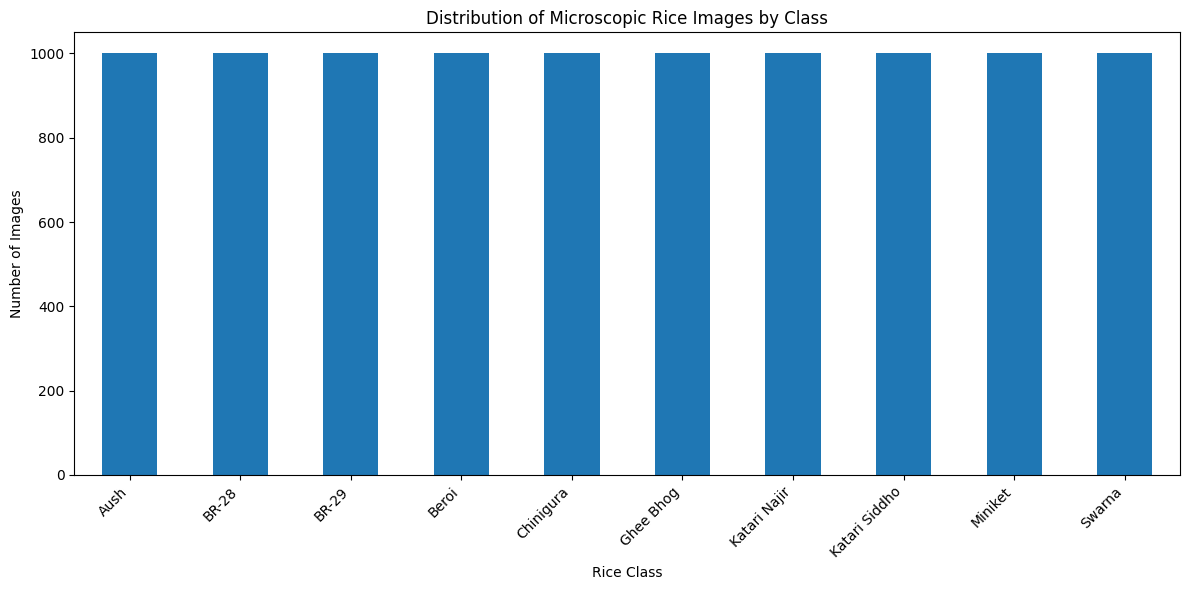

In [13]:
class_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(12, 6))
class_counts.plot(kind="bar")

plt.title("Distribution of Microscopic Rice Images by Class")
plt.xlabel("Rice Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Original vs Augmented Images

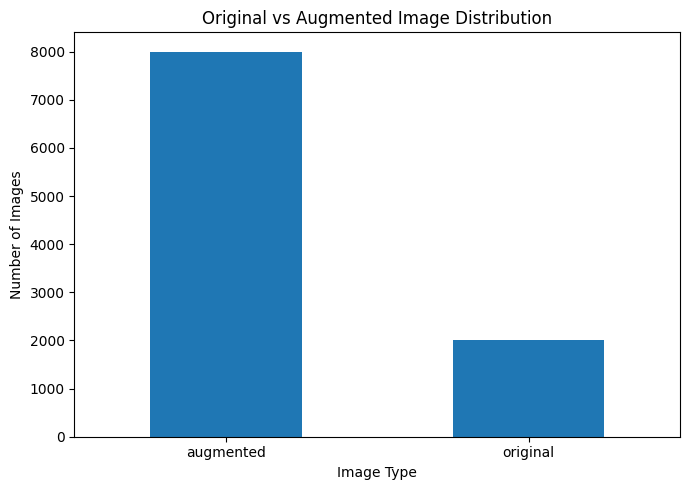

,Image Count
dataset_type,
augmented,8000
original,2000


In [14]:
type_counts = df["dataset_type"].value_counts()

plt.figure(figsize=(7, 5))
type_counts.plot(kind="bar")

plt.title("Original vs Augmented Image Distribution")
plt.xlabel("Image Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(type_counts.to_frame("Image Count"))

## 10. Class-wise Original and Augmented Counts

dataset_type,augmented,original
label,,
Aush,800,200
BR-28,800,200
BR-29,800,200
Beroi,800,200
Chinigura,800,200
Ghee Bhog,800,200
Katari Najir,800,200
Katari Siddho,800,200
Miniket,800,200


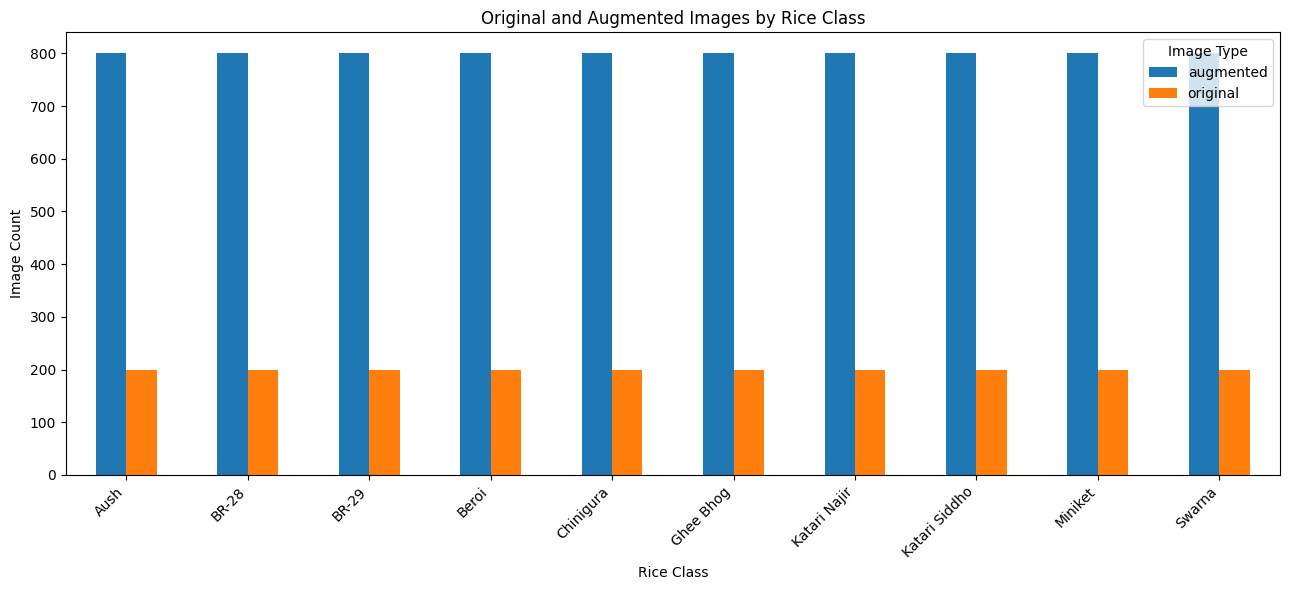

In [15]:
class_type_counts = pd.crosstab(
    df["label"],
    df["dataset_type"]
)

display(class_type_counts)

class_type_counts.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Original and Augmented Images by Rice Class")
plt.xlabel("Rice Class")
plt.ylabel("Image Count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Image Type")
plt.tight_layout()
plt.show()

## 11. Preview Sample Microscopic Images

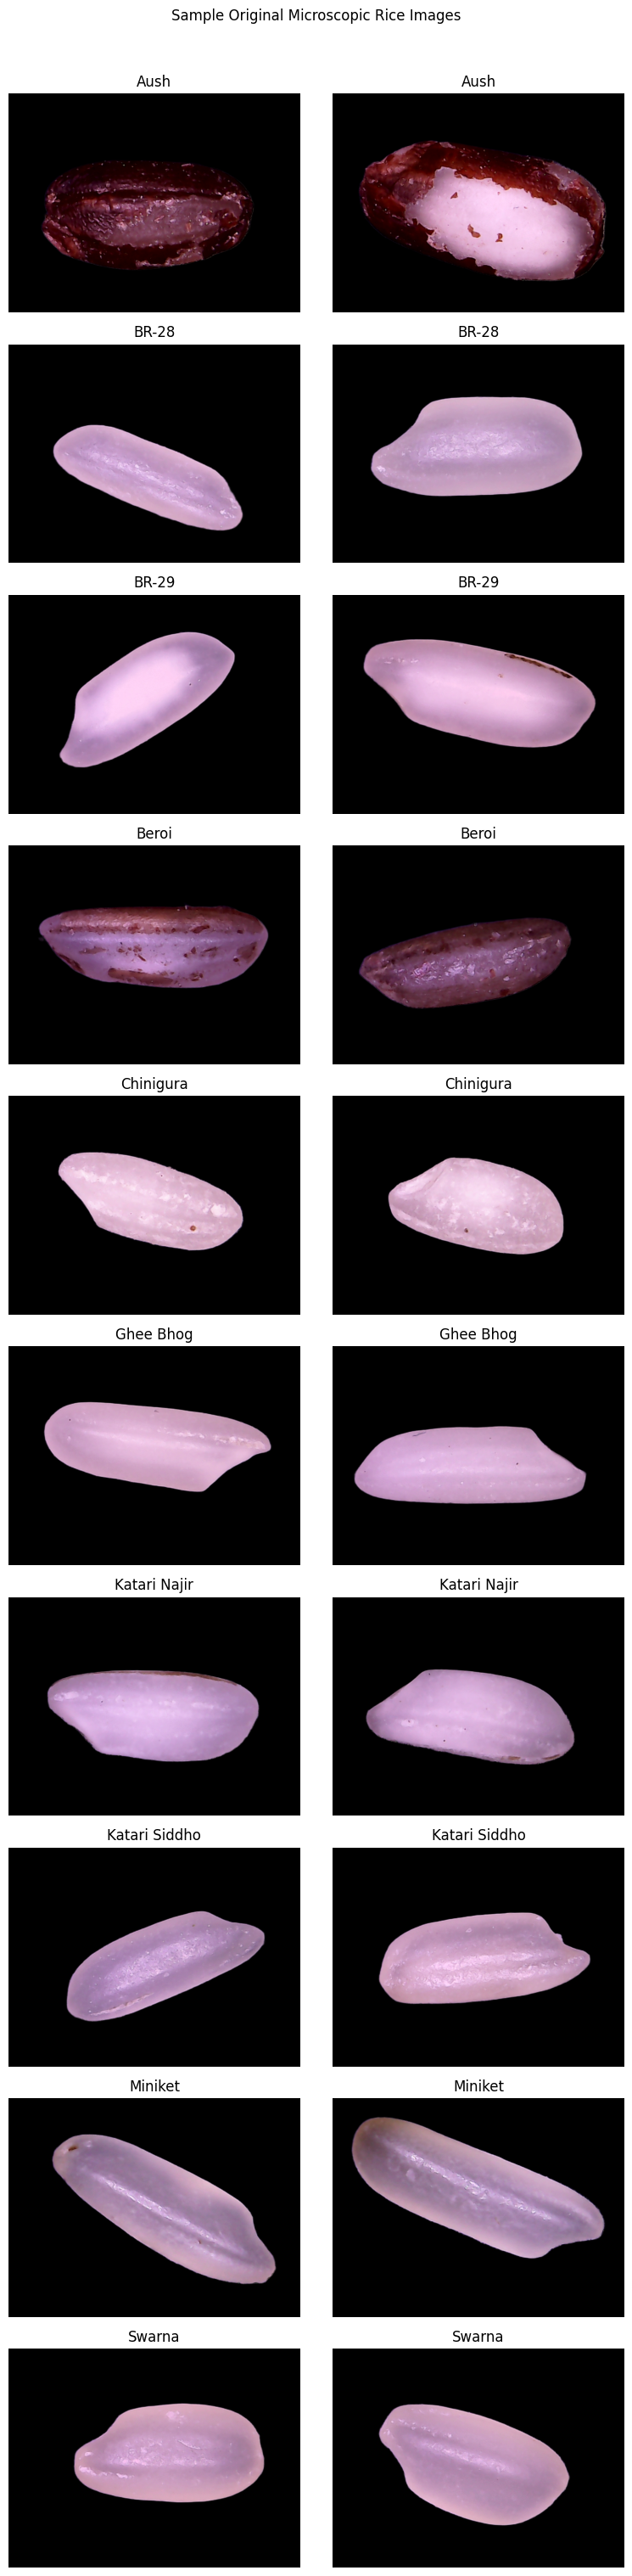

In [16]:
original_df = df[df["dataset_type"] == "original"]

labels = sorted(original_df["label"].unique())
n_per_class = 2

fig, axes = plt.subplots(
    len(labels),
    n_per_class,
    figsize=(8, 3 * len(labels))
)

axes = np.array(axes).reshape(len(labels), n_per_class)

for i, label in enumerate(labels):
    samples = original_df[
        original_df["label"] == label
    ].sample(
        n=min(n_per_class, len(
            original_df[original_df["label"] == label]
        )),
        random_state=SEED
    )

    for j in range(n_per_class):
        axes[i, j].axis("off")

        if j < len(samples):
            row = samples.iloc[j]

            try:
                img = Image.open(row["image_path"]).convert("RGB")
                axes[i, j].imshow(img)
                axes[i, j].set_title(label)
            except Exception as e:
                axes[i, j].set_title("Image could not be opened")

plt.suptitle("Sample Original Microscopic Rice Images", y=1.01)
plt.tight_layout()
plt.show()

## 12. Image Dimensions and Color Modes

In [17]:
sample_df = df.sample(
    n=min(500, len(df)),
    random_state=SEED
)

image_stats = []

for row in sample_df.itertuples(index=False):
    try:
        with Image.open(row.image_path) as img:
            image_stats.append({
                "label": row.label,
                "dataset_type": row.dataset_type,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "size_kb": os.path.getsize(row.image_path) / 1024
            })
    except Exception:
        pass

image_stats_df = pd.DataFrame(image_stats)

print("Images successfully inspected:", len(image_stats_df))
display(image_stats_df.head())

print("\nDimension summary:")
display(
    image_stats_df[["width", "height", "size_kb"]].describe()
)

print("\nColor modes:")
display(image_stats_df["mode"].value_counts())

Images successfully inspected: 500


,label,dataset_type,width,height,mode,size_kb
0,Aush,augmented,640,480,RGB,33.145508
1,Ghee Bhog,augmented,640,480,RGB,24.405273
2,Beroi,augmented,640,480,RGB,27.283203
3,Ghee Bhog,augmented,640,480,RGB,21.917969
4,Ghee Bhog,augmented,640,480,RGB,24.309570



Dimension summary:


,width,height,size_kb
count,500.0,500.0,500.000000
mean,640.0,480.0,43.570803
std,0.0,0.0,39.660711
min,640.0,480.0,15.479492
25%,640.0,480.0,21.665283
50%,640.0,480.0,25.745605
75%,640.0,480.0,36.114746
max,640.0,480.0,226.424805



Color modes:


,count
mode,
RGB,406
RGBA,94


## 13. Visualize Image Dimensions

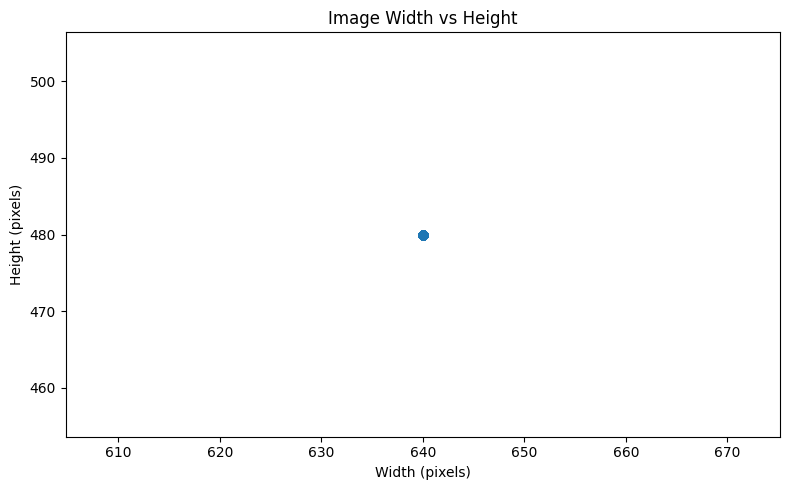

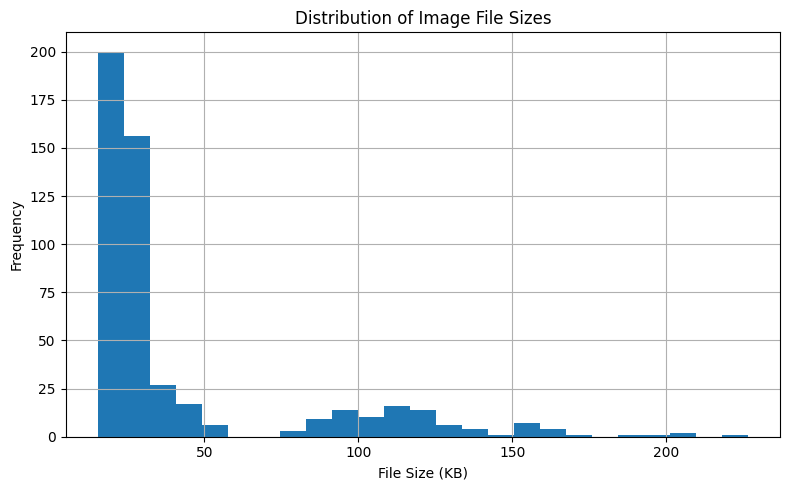

In [18]:
if not image_stats_df.empty:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        image_stats_df["width"],
        image_stats_df["height"],
        alpha=0.6
    )

    plt.title("Image Width vs Height")
    plt.xlabel("Width (pixels)")
    plt.ylabel("Height (pixels)")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    image_stats_df["size_kb"].hist(bins=25)

    plt.title("Distribution of Image File Sizes")
    plt.xlabel("File Size (KB)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 14. Check Class Imbalance

In [19]:
original_counts = (
    df[df["dataset_type"] == "original"]["label"]
    .value_counts()
    .sort_index()
)

print("Original image counts by class:")
display(original_counts.to_frame("Original Count"))

if len(original_counts) > 0 and original_counts.min() > 0:
    imbalance_ratio = original_counts.max() / original_counts.min()

    print("Maximum class count:", original_counts.max())
    print("Minimum class count:", original_counts.min())
    print("Max/min imbalance ratio:", round(imbalance_ratio, 3))
else:
    print("Cannot calculate the imbalance ratio.")

Original image counts by class:


,Original Count
label,
Aush,200
BR-28,200
BR-29,200
Beroi,200
Chinigura,200
Ghee Bhog,200
Katari Najir,200
Katari Siddho,200
Miniket,200


Maximum class count: 200
Minimum class count: 200
Max/min imbalance ratio: 1.0


## 15. Check Corrupted or Unreadable Images

In [20]:
bad_images = []

for row in df.itertuples(index=False):
    try:
        with Image.open(row.image_path) as img:
            img.verify()
    except Exception as e:
        bad_images.append({
            "image_path": row.image_path,
            "error": str(e)
        })

bad_images_df = pd.DataFrame(bad_images)

print("Total images:", len(df))
print("Unreadable/corrupted images:", len(bad_images_df))

if not bad_images_df.empty:
    display(bad_images_df.head(20))
else:
    print("No unreadable images were detected.")

Total images: 10000
Unreadable/corrupted images: 0
No unreadable images were detected.


## 16. Save EDA Results

In [21]:
OUTPUT_DIR = "/content/eda_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df.to_csv(
    f"{OUTPUT_DIR}/rice_image_metadata.csv",
    index=False
)

class_counts.rename("image_count").to_csv(
    f"{OUTPUT_DIR}/class_distribution.csv"
)

class_type_counts.to_csv(
    f"{OUTPUT_DIR}/class_type_distribution.csv"
)

image_stats_df.to_csv(
    f"{OUTPUT_DIR}/image_statistics_sample.csv",
    index=False
)

bad_images_df.to_csv(
    f"{OUTPUT_DIR}/unreadable_images.csv",
    index=False
)

print("EDA result files saved in:", OUTPUT_DIR)

EDA result files saved in: /content/eda_results


## Part 2: Related-Work Table + Research Gap

## 17. Create Related-Work Table (Code)

In [23]:

import pandas as pd
from IPython.display import display

papers = [
    {
        "Author and Year": "Islam et al. (2025)",
        "Paper Title": "Rice Variety Classification Using Next Generation Convolutional Networks",
        "Dataset and Image Type": "Two rice-image datasets",
        "Method": "CNN with Transformer-inspired design",
        "Reported Results": "99.60% and 100% accuracy on two datasets",
        "Limitation / Gap": "Performance on the target PRBD processed-rice dataset is not established",
        "URL": "https://doi.org/10.1049/tje2.70102"
    },
    {
        "Author and Year": "Farahnakian et al. (2024)",
        "Paper Title": "A Comparative Study of State-of-the-art Deep Learning Architectures for Rice Grain Classification",
        "Dataset and Image Type": "75,000 images, five rice categories",
        "Method": "ResNet, VGG, EfficientNet, MobileNet",
        "Reported Results": "EfficientNet achieved 99.67% accuracy",
        "Limitation / Gap": "Results may not transfer directly to microscopic processed-rice images",
        "URL": "https://doi.org/10.1016/j.jafr.2023.100890"
    },
    {
        "Author and Year": "Shuvo et al. (2026)",
        "Paper Title": "Image-based Classification of Bangladeshi Rice Varieties Using Deep CNNs",
        "Dataset and Image Type": "15,000 images, five Bangladeshi varieties",
        "Method": "VGG16, VGG19, ResNet50, Xception, DenseNet, custom CNN",
        "Reported Results": "VGG19: 99.73%; custom model: 98.60%",
        "Limitation / Gap": "The target PRBD processed-rice dataset needs separate evaluation",
        "URL": "https://doi.org/10.1007/s44462-026-00061-9"
    },
    {
        "Author and Year": "Tahsin et al. (2024)",
        "Paper Title": "An Extensive Image Dataset for Deep Learning-based Classification of Rice Kernel Varieties in Bangladesh",
        "Dataset and Image Type": "38 varieties; 19,000 original and 57,000 augmented microscopic images",
        "Method": "Dataset creation and image augmentation",
        "Reported Results": "Dataset contribution; no model-comparison accuracy benchmark",
        "Limitation / Gap": "A model benchmark is still needed for the target classification task",
        "URL": "https://doi.org/10.1016/j.dib.2024.111109"
    },
    {
        "Author and Year": "Arnab et al. (2025)",
        "Paper Title": "RiceKernelEngine: Benchmarking Transfer Learning Models for Microscopic Images of Rice Kernel",
        "Dataset and Image Type": "3,155 microscopic images, five varieties",
        "Method": "VGG19, MobileNetV3, EfficientNet, ConvNeXt",
        "Reported Results": "EfficientNet: 96%; MobileNetV3: 94%; ConvNeXt: 87%; VGG19: 85%",
        "Limitation / Gap": "Performance on the PRBD dataset remains to be tested",
        "URL": "https://doi.org/10.1016/j.array.2025.100429"
    }
]

df = pd.DataFrame(papers)

display(df)

df.to_csv("/content/related_work.csv", index=False)

print("Related-work table saved successfully.")


,Author and Year,Paper Title,Dataset and Image Type,Method,Reported Results,Limitation / Gap,URL
0,Islam et al. (2025),Rice Variety Classification Using Next Generat...,Two rice-image datasets,CNN with Transformer-inspired design,99.60% and 100% accuracy on two datasets,Performance on the target PRBD processed-rice ...,https://doi.org/10.1049/tje2.70102
1,Farahnakian et al. (2024),A Comparative Study of State-of-the-art Deep L...,"75,000 images, five rice categories","ResNet, VGG, EfficientNet, MobileNet",EfficientNet achieved 99.67% accuracy,Results may not transfer directly to microscop...,https://doi.org/10.1016/j.jafr.2023.100890
2,Shuvo et al. (2026),Image-based Classification of Bangladeshi Rice...,"15,000 images, five Bangladeshi varieties","VGG16, VGG19, ResNet50, Xception, DenseNet, cu...",VGG19: 99.73%; custom model: 98.60%,The target PRBD processed-rice dataset needs s...,https://doi.org/10.1007/s44462-026-00061-9
3,Tahsin et al. (2024),An Extensive Image Dataset for Deep Learning-b...,"38 varieties; 19,000 original and 57,000 augme...",Dataset creation and image augmentation,Dataset contribution; no model-comparison accu...,A model benchmark is still needed for the targ...,https://doi.org/10.1016/j.dib.2024.111109
4,Arnab et al. (2025),RiceKernelEngine: Benchmarking Transfer Learni...,"3,155 microscopic images, five varieties","VGG19, MobileNetV3, EfficientNet, ConvNeXt",EfficientNet: 96%; MobileNetV3: 94%; ConvNeXt:...,Performance on the PRBD dataset remains to be ...,https://doi.org/10.1016/j.array.2025.100429


Related-work table saved successfully.


## 18. CSV file download

In [24]:

from google.colab import files

files.download("/content/related_work.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Research gap

### Research Gap

Previous studies have applied deep learning and transfer learning techniques to rice image classification and have reported high classification accuracy on different datasets. Several studies have compared architectures such as VGG, ResNet, EfficientNet, MobileNet, and custom CNNs. Other research has contributed microscopic rice image datasets, including images of processed or semi-processed rice.

However, the reviewed studies differ in dataset composition, rice categories, image acquisition conditions, and evaluation procedures. Therefore, their reported performance cannot be directly generalized to the PRBD Microscopic Image of Different Processed Rice dataset.

A dataset-specific evaluation is needed to assess how effectively selected image-classification models distinguish the ten rice categories in PRBD. The study can compare model performance using accuracy, precision, recall, F1-score, and a confusion matrix. Careful data splitting is also necessary to prevent images derived from the same original source from appearing in both training and testing sets.

**Proposed research gap:** A systematic evaluation of selected image-classification models on the PRBD dataset, using a consistent evaluation procedure and a data-splitting strategy that minimizes data leakage.